# Módulo 1B — Ciclos límite y bifurcación de Hopf

**Objetivos.** Identificar candidatos de Hopf, visualizar oscilaciones, estimar amplitud y período, y distinguir evidencia numérica de demostraciones matemáticas.

Una órbita periódica no constante cumple $X(T)=X(0)$ para $T>0$. Es un **ciclo límite** si su órbita está aislada entre las órbitas periódicas. El jacobiano solo informa la dinámica local cerca del equilibrio; no determina por sí solo existencia ni estabilidad de ciclos.

**Visualización:** los gráficos aparecen en Jupyter sin guardarse. Hay deslizadores para estudiar el comportamiento al cambiar $I$ y una animación con reproducción/pausa.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from dataclasses import replace

# Ejecuta Jupyter desde la raíz del repositorio o desde notebooks/
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Abre Jupyter desde la raíz del repositorio o desde notebooks/.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from fhn_control.models import FHNParameters, rhs, equilibrium, jacobian, hopf_candidates
from fhn_control.visualization import plot_phase_portrait, animate_trajectory

## 1. Condiciones candidatas de Hopf

Del jacobiano del primer notebook,

$$\operatorname{tr}J=1-(v^*)^2-\frac b\tau,\qquad \det J=\frac{1-b+b(v^*)^2}{\tau}>0.$$

Para autovalores puramente imaginarios se exige $\operatorname{tr}J=0$, así que

$$v^*_{\pm}=\pm\sqrt{1-b/\tau},\qquad I^*_{\pm}=\frac{(v^*_{\pm})^3}{3}+\left(\frac1b-1\right)v^*_{\pm}+\frac ab.$$

Esta fórmula para $I^*$ requiere $b>0$ y $\tau>b$. Para $0<b<\tau$ y $v^*\neq0$ vale la transversalidad

$$\frac{d}{dI}\operatorname{tr}J=-\frac{2bv^*}{1-b+b(v^*)^2}\neq0.$$

**Advertencia:** falta comprobar la no degeneración mediante el primer coeficiente de Lyapunov para afirmar un Hopf genérico y clasificarlo como super/subcrítico. Las figuras que siguen no reemplazan esa demostración.

In [2]:
p=FHNParameters(a=0.7,b=0.8,tau=12.5,I=0.9)
for vcrit,Icrit in hopf_candidates(p):
 pc=replace(p,I=Icrit)
 ev=np.linalg.eigvals(jacobian(vcrit,pc))
 dtrace=-2*p.b*vcrit/(1-p.b+p.b*vcrit*vcrit)
 print(f'v*={vcrit:.6f}, I*={Icrit:.6f}, autovalores={ev}, d(traza)/dI={dtrace:.6f}')


v*=-0.967471, I*=0.331281, autovalores=[0.+0.27550681j 0.-0.27550681j], d(traza)/dI=1.631486
v*=0.967471, I*=1.418719, autovalores=[0.+0.27550681j 0.-0.27550681j], d(traza)/dI=-1.631486


## 2. Comparación de tres regímenes

Se integran las EDO con iguales $a,b,\tau$ pero distintos $I$: un equilibrio atractivo a la izquierda, un régimen oscilatorio intermedio y otro equilibrio atractivo a la derecha. Los límites son visuales y dependen de los parámetros elegidos.

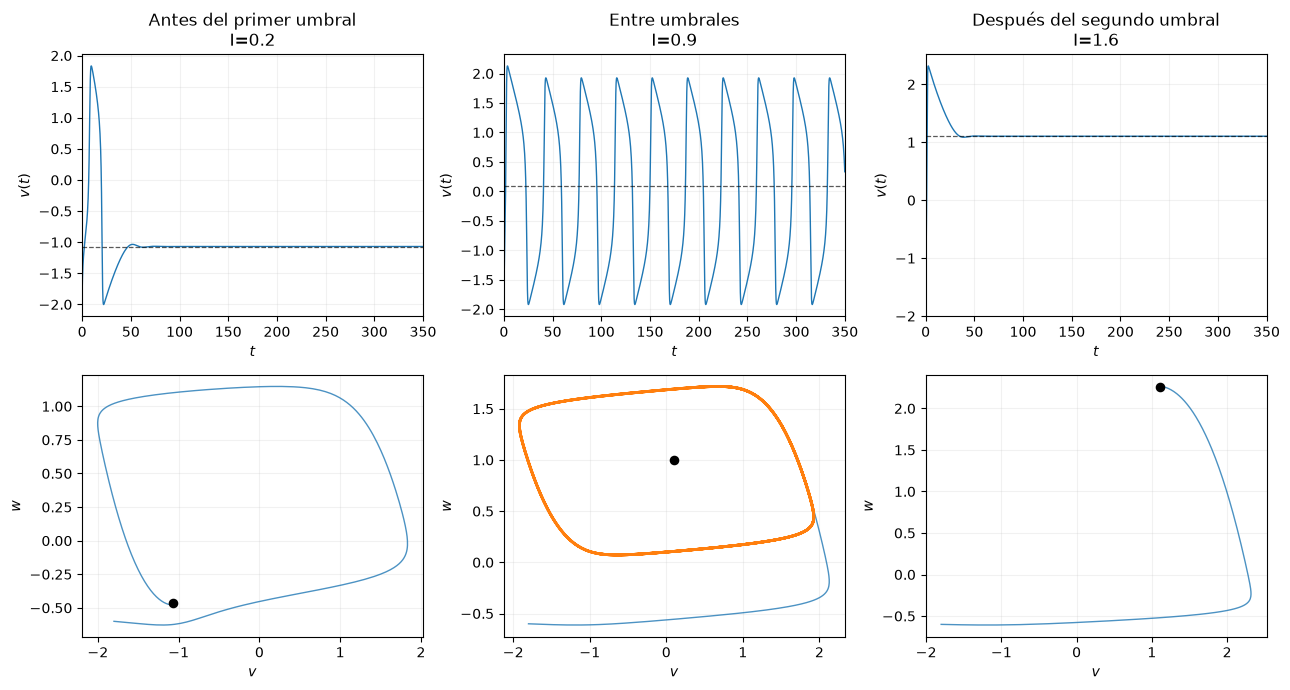

In [3]:
regimes=[('Antes del primer umbral',0.2),('Entre umbrales',0.9),('Después del segundo umbral',1.6)]
fig,axs=plt.subplots(2,3,figsize=(13,7))
for j,(name,I) in enumerate(regimes):
 pp=replace(p,I=I)
 eq=equilibrium(pp)
 sol=solve_ivp(lambda t,x:rhs(t,x,pp),(0,350),[-1.8,-.6],max_step=.25,rtol=1e-8,atol=1e-10)
 axs[0,j].plot(sol.t,sol.y[0],lw=1)
 axs[0,j].axhline(eq[0],color='black',ls='--',lw=.9,alpha=.65)
 axs[0,j].set(xlim=(0,350),xlabel='$t$',ylabel='$v(t)$',title=f'{name}\nI={I}')
 axs[1,j].plot(sol.y[0],sol.y[1],lw=1.0,alpha=.8)
 axs[1,j].plot(sol.y[0,sol.t>220],sol.y[1,sol.t>220],lw=2)
 axs[1,j].scatter(*eq,s=35,color='black',zorder=4)
 axs[1,j].set(xlabel='$v$',ylabel='$w$')
for ax in axs.flat:ax.grid(alpha=.17)
fig.tight_layout();plt.show()


## 3. Estimar amplitud y período de una oscilación

Cuando hay un ciclo límite atractivo, las oscilaciones después de un transitorio deberían repetirse. Estimaremos:

- amplitud pico-a-pico de $v$ en el último tramo temporal;
- período usando picos consecutivos de $v(t)$.

Los resultados no prueban por sí solos que la solución sea exactamente periódica. Cerca de un umbral de Hopf hay transitorios lentos: conviene integrar tiempos mayores y repetir desde distintas condiciones iniciales.

Amplitud pico-a-pico estimada: 3.84488
Período estimado: 36.45000 (a partir de 8 intervalos entre picos)


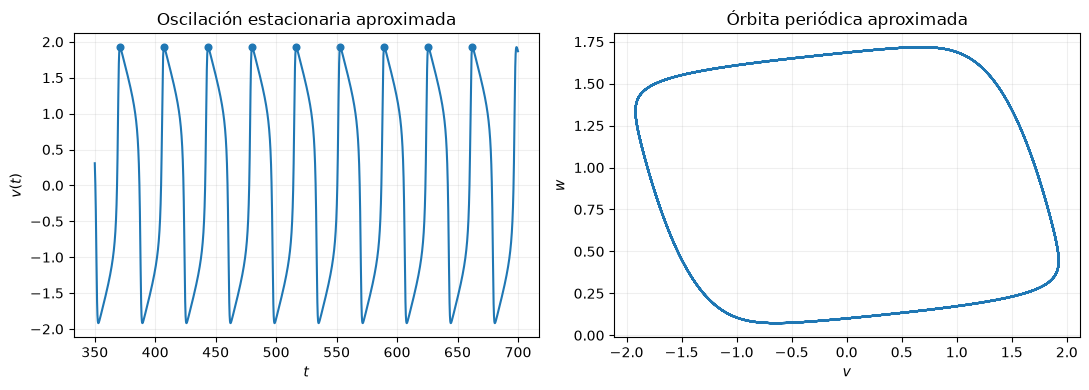

In [4]:
from scipy.signal import find_peaks
pp=replace(p,I=.9)
sol=solve_ivp(lambda t,x:rhs(t,x,pp),(0,700),[-1.8,-.6],t_eval=np.linspace(0,700,14001),rtol=1e-8,atol=1e-10)
mask=sol.t>350
tail_t=sol.t[mask]; tail_v=sol.y[0,mask]; tail_w=sol.y[1,mask]
peaks,_=find_peaks(tail_v,prominence=.2,distance=100)
amp_pp=tail_v.max()-tail_v.min()
periods=np.diff(tail_t[peaks]);period=float(np.median(periods)) if len(periods) else float('nan')
print(f'Amplitud pico-a-pico estimada: {amp_pp:.5f}')
print(f'Período estimado: {period:.5f} (a partir de {len(periods)} intervalos entre picos)')
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(tail_t,tail_v);axs[0].scatter(tail_t[peaks],tail_v[peaks],s=23)
axs[0].set(xlabel='$t$',ylabel='$v(t)$',title='Oscilación estacionaria aproximada')
axs[1].plot(tail_v,tail_w);axs[1].set(xlabel='$v$',ylabel='$w$',title='Órbita periódica aproximada')
for ax in axs:ax.grid(alpha=.2)
fig.tight_layout();plt.show()


## 4. Diagrama de amplitud versus forzamiento

La amplitud pico-a-pico estimada se calcula en un tramo tardío de la simulación para distintos valores de $I$. Cerca de Hopf puede haber **falsos positivos** de amplitud por transitorios, por lo que la figura se interpreta como exploratoria, no como un diagrama de bifurcación riguroso.

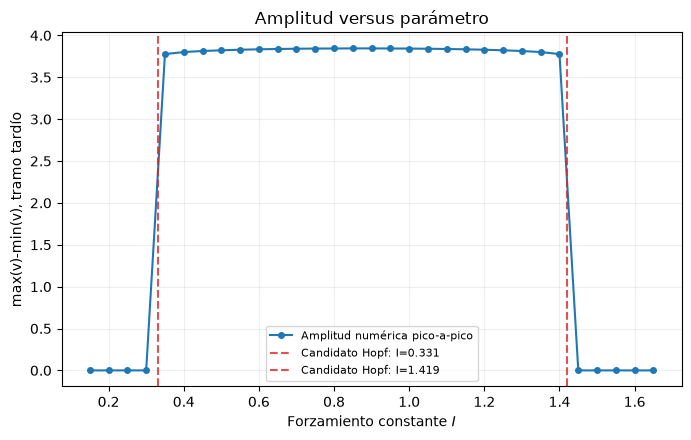

In [5]:
from scipy.signal import find_peaks
I_values=np.linspace(.15,1.65,31)
values=[]
for I in I_values:
 pp=replace(p,I=float(I))
 sol=solve_ivp(lambda t,x:rhs(t,x,pp),(0,650),[-1.8,-.6],t_eval=np.linspace(0,650,2601),rtol=1e-7,atol=1e-9)
 late=sol.y[0,sol.t>450]
 values.append(float(late.max()-late.min()))
fig,ax=plt.subplots(figsize=(8,4.6))
ax.plot(I_values,values,'o-',ms=4,label='Amplitud numérica pico-a-pico')
for vcrit,Icrit in hopf_candidates(p): ax.axvline(Icrit,color='tab:red',ls='--',alpha=.8,label=f'Candidato Hopf: I={Icrit:.3f}')
ax.set(xlabel='Forzamiento constante $I$',ylabel='max(v)-min(v), tramo tardío',title='Amplitud versus parámetro')
ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.show()


## 5. Criterio geométrico de existencia: Poincaré–Bendixson

Si una órbita positiva permanece en un compacto y su conjunto $\omega$-límite no contiene equilibrios, entonces dicho conjunto es una órbita periódica.

Una función útil para construir una región de atrapamiento es

$$V(v,w)=\frac12(v^2+\tau w^2),\qquad \dot V=v^2-\frac{v^4}{3}+Iv+aw-bw^2.$$

Con $b>0$, los términos negativos dominan fuera de un conjunto grande, permitiendo construir una región compacta atrapante. Si el único equilibrio es una fuente hiperbólica, puede excluirse como límite de trayectorias distintas de él y aplicar Poincaré–Bendixson. Una demostración completa debe detallar la región atrapante y el argumento de exclusión.

## 6. Qué está demostrado y qué queda pendiente

**Analíticamente:** unicidad del equilibrio, jacobiano, clasificación local para traza no nula, candidatos de Hopf y transversalidad (para $0<b<\tau$).

**Numéricamente:** retratos de fase, estimación de amplitudes y períodos, evidencia de ciclos atractivos.

**Pendiente para afirmar Hopf genérico:** cálculo del primer coeficiente de Lyapunov y justificación de estabilidad de la rama periódica. Para precisión alta de la órbita: mapa de retorno, shooting o continuación numérica. La sincronización entre neuronas pertenece al módulo posterior.

## 6. Laboratorio interactivo: del equilibrio a la oscilación

En el intervalo de parámetros considerado, los dos valores críticos obtenidos arriba delimitan una zona de traza positiva. Desplaza $I$ y compara una trayectoria en el plano $(v,w)$ con la señal $v(t)$. 

**Importante:** un ciclo límite atractivo puede coexistir con otras estructuras dinámicas. La amplitud del tramo final y las curvas cerradas aparentes son **evidencia numérica**, no una demostración de una bifurcación de Hopf no degenerada.

In [6]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

base = FHNParameters(a=0.7,b=0.8,tau=12.5,I=0.9)
I_hopf = widgets.FloatSlider(value=.9,min=0,max=1.8,step=.025,
                            description='I',continuous_update=False,readout_format='.3f')
pert_v = widgets.FloatSlider(value=.1,min=-.5,max=.5,step=.05,
                             description='delta v',continuous_update=False)
pert_w = widgets.FloatSlider(value=.08,min=-.5,max=.5,step=.05,
                             description='delta w',continuous_update=False)
T_hopf = widgets.IntSlider(value=350,min=80,max=700,step=20,
                           description='Tiempo',continuous_update=False)

def dibujar_hopf(I, dv, dw, T):
    pp=replace(base,I=I)
    eq=equilibrium(pp)
    sol=solve_ivp(lambda t,x:rhs(t,x,pp),(0,T),eq+np.array([dv,dw]),
                  t_eval=np.linspace(0,T,1800),rtol=1e-8,atol=1e-10)
    tr=float(np.trace(jacobian(eq[0],pp)))
    late=sol.y[0,sol.t>0.7*T]
    amp=float(np.ptp(late))
    print(f'traza(J*) = {tr:.4f}; amplitud pico-a-pico observada (último 30%) = {amp:.4f}')
    fig, axs = plt.subplots(1,2,figsize=(11,4.3))
    plot_phase_portrait(axs[0],pp,sol=sol,show_nullclines=False,
                        xlim=(-2.6,2.6),ylim=(-1.8,2.9),tail_fraction=.3)
    axs[0].set_title('Trayectoria y tramo final resaltado')
    axs[1].plot(sol.t,sol.y[0],lw=1.2)
    axs[1].axhline(eq[0],color='black',ls='--',alpha=.5,label='v*')
    axs[1].set(xlabel='t',ylabel='v(t)',title='Oscilación en el tiempo')
    axs[1].legend();axs[1].grid(alpha=.2)
    fig.tight_layout();plt.show()

salida_hopf=widgets.interactive_output(dibujar_hopf,
                   {'I':I_hopf,'dv':pert_v,'dw':pert_w,'T':T_hopf})
display(widgets.VBox([widgets.HBox([I_hopf,T_hopf]),
                      widgets.HBox([pert_v,pert_w])]),salida_hopf)

Output()

## 7. Animación de la oscilación en el plano de fases

La curva se traza conforme avanza el tiempo y el punto señala la posición actual. A la derecha se muestra $v(t)$ con el tiempo sincronizado. Cambia $I$ y observa cómo la solución puede aproximarse al equilibrio o mantener oscilaciones.

Presiona el botón para generar una animación usando los controles del apartado anterior. El reproductor se ejecuta **dentro de Jupyter**, sin guardar archivos.

In [ ]:
boton_hopf=widgets.Button(description='Animar esta trayectoria',button_style='info',icon='play')
salida_anim_hopf=widgets.Output()

def reproducir_hopf(_):
    with salida_anim_hopf:
        clear_output(wait=True)
        pp=replace(base,I=I_hopf.value)
        eq=equilibrium(pp)
        T=T_hopf.value
        sol=solve_ivp(lambda t,x:rhs(t,x,pp),(0,T),
                      eq+np.array([pert_v.value,pert_w.value]),
                      t_eval=np.linspace(0,T,650),rtol=1e-8,atol=1e-10)
        anim=animate_trajectory(sol,pp,max_frames=115,
                                title=f'Ciclo/órbita para I={pp.I:.3f}')
        display(HTML(anim.to_jshtml(fps=20,default_mode='once')))
        plt.close(anim._fig)

boton_hopf.on_click(reproducir_hopf)
display(boton_hopf,salida_anim_hopf)

Button(button_style='info', description='Animar esta trayectoria', icon='play', style=ButtonStyle())

Output()